## Machine Learning Modeling
The next stage involves preparing the feature-engineered dataset for machine learning, including selecting the input features, splitting the data into training and testing sets, and getting it ready for model development.

In [1]:
# pandas & numpy -> work with tables of data (like Excel, but in code)
import pandas as pd
import numpy as np

# matplotlib & seaborn -> draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn -> machine learning tools (models, splitting data, scoring)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, RocCurveDisplay)

# Make charts look nice and consistent
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

print("All libraries loaded successfully ✅")

All libraries loaded successfully ✅


In [2]:
import pickle

In [3]:
df = pd.read_csv("feature_engineered_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (50000, 34)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status,experience_category,academic_avg,academic_band,skills_match_level,interview_avg_score,interview_performance_category,placement_probability_score,placement_probability_band
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,2,No,1,Willing,Relevant,3.530557,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed,Junior,74.920254,Good,High,70.754233,Average,60.1,Medium
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,1,Yes,0,Not Willing,Relevant,0.000000,10.807739,Tier 1,Matched,High,Required,0.0,No,0.0,Not Willing,Not Placed,Fresher,68.650839,Good,Medium,62.532418,Average,46.5,Low
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,1,Yes,1,Willing,Relevant,5.801817,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed,Junior,77.641017,Excellent,High,70.175622,Average,63.3,Medium
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,2,No,0,Not Willing,Relevant,0.000000,9.980580,Tier 2,Matched,Low,Not Required,0.0,No,6.0,Willing,Not Placed,Fresher,75.329142,Excellent,Medium,64.539376,Average,59.3,Medium
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,1,No,0,Willing,Not Relevant,0.000000,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed,Fresher,69.021094,Good,High,65.146274,Average,56.4,Medium


## Prepare Data for Machine Learning

Before training the models, we prepare the dataset by defining `status` as the target variable, encoding categorical features into numerical values using one-hot encoding, splitting the data into 80% training and 20% testing sets, and scaling numerical features to bring them to a comparable range.

In [4]:
# 1. Define the target variable
# Business-focused mapping:
#   Placed     -> Job Accepted (1)
#   Not Placed -> Job Rejected (0)
df['target'] = df['status'].map({'Placed': 1, 'Not Placed': 0})
df['target'].value_counts()

target
0    34870
1    15130
Name: count, dtype: int64

In [5]:
# 2. One-hot encode categorical columns
# We drop 'status' (already encoded as 'target') to avoid leaking the answer
model_df = df.drop(columns=['status'])

categorical_features = model_df.select_dtypes(include='object').columns.tolist()
print("Categorical columns to encode:", categorical_features)

# pd.get_dummies() converts categorical text columns into separate 0/1 columns.
model_df_encoded = pd.get_dummies(model_df, columns=categorical_features, drop_first=True)
print("Shape after encoding:", model_df_encoded.shape)

Categorical columns to encode: ['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'experience_category', 'academic_band', 'skills_match_level', 'interview_performance_category', 'placement_probability_band']
Shape after encoding: (50000, 44)


In [7]:
# 3. Split features (X) and target (y)
X = model_df_encoded.drop(columns=['target'])
y = model_df_encoded['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print("Training set size:", y_train.shape)
print("Testing set size:", y_test.shape)

Training set size: (40000, 43)
Testing set size: (10000, 43)
Training set size: (40000,)
Testing set size: (10000,)


In [9]:
# 4. Scale numeric features (needed for Logistic Regression; tree models don't need it,
# but scaling doesn't hurt them either — we keep a scaled copy for models that need it)
numeric_feature_cols = X_train.select_dtypes(include=np.number).columns.tolist()

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_feature_cols] = scaler.fit_transform(X_train[numeric_feature_cols])
X_test_scaled[numeric_feature_cols] = scaler.transform(X_test[numeric_feature_cols])

print("Scaling done ✅")

Scaling done ✅


## Train Machine Learning Models

Since this is a **classification** problem (Placed vs Not Placed), we'll try three common,
beginner-friendly models and compare them:

1. **Logistic Regression** — a simple, fast, interpretable baseline
2. **Decision Tree** — easy to visualize/explain, captures non-linear patterns
3. **Random Forest** — an ensemble of many decision trees, usually more accurate

In [10]:
results = {}

# 1. Logistic Regression (uses scaled data)
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
pred_lr = log_reg.predict(X_test_scaled)
prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# 2. Decision Tree (raw data is fine)
dtree = DecisionTreeClassifier(max_depth=8, random_state=42)
dtree.fit(X_train, y_train)
pred_dt = dtree.predict(X_test)
prob_dt = dtree.predict_proba(X_test)[:, 1]

# 3. Random Forest (raw data is fine)
rforest = RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42)
rforest.fit(X_train, y_train)
pred_rf = rforest.predict(X_test)
prob_rf = rforest.predict_proba(X_test)[:, 1]

print("All 3 models trained ✅")

All 3 models trained ✅


## Evaluate the Models

We assess each model using multiple performance metrics to understand how accurately it predicts candidate placement outcomes. These include accuracy, precision, recall, F1-score, and AUC, which help evaluate overall correctness, the identification of placed candidates, and the model's ability to distinguish between the two classes.

In [11]:
def evaluate(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-score': f1_score(y_true, y_pred),
        'AUC': roc_auc_score(y_true, y_prob),
    }

results_table = pd.DataFrame([
    evaluate("Logistic Regression", y_test, pred_lr, prob_lr),
    evaluate("Decision Tree", y_test, pred_dt, prob_dt),
    evaluate("Random Forest", y_test, pred_rf, prob_rf),
]).set_index('Model').round(3)

results_table

,Accuracy,Precision,Recall,F1-score,AUC
Model,,,,,
Logistic Regression,0.861,0.787,0.741,0.763,0.931
Decision Tree,0.828,0.728,0.691,0.709,0.899
Random Forest,0.870,0.842,0.704,0.767,0.942


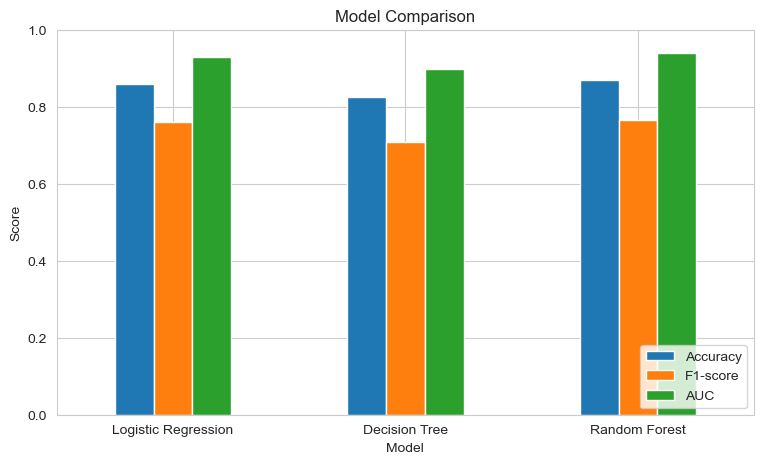

In [27]:
results_table[['Accuracy', 'F1-score', 'AUC']].plot(kind='bar', figsize=(9,5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

**🔍 Insight:** All three models land in a similar ballpark, but Random Forest edges out the others on Accuracy and AUC — meaning it's both the most correct overall and the best at ranking candidates by how likely they are to accept an offer.

###  Confusion Matrix (best model)
Let's look closer at the Random Forest model — how many candidates did it correctly / incorrectly classify?

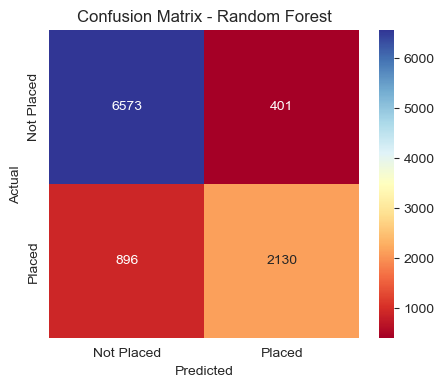

In [26]:
cm = confusion_matrix(y_test, pred_rf)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdYlBu',
            xticklabels=['Not Placed', 'Placed'], yticklabels=['Not Placed', 'Placed'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()

**🔍 Insight:** The model correctly identifies the large majority of both Placed and Not Placed candidates. Most of its mistakes are 'false negatives' — candidates who actually accepted but the model predicted wouldn't — which is the safer kind of error for this business use case (better to double-check a candidate than to write them off).

The Random Forest model correctly classified 8,703 out of 10,000 candidates, achieving 87.03% accuracy. It correctly identified 6,573 candidates as Not Placed and 2,130 candidates as Placed. However, it made 1,297 incorrect predictions, including 896 false negatives and 401 false positives. This indicates that the model performs better at identifying candidates who are Not Placed than candidates who are Placed. Improving the detection of placed candidates could help make the model more useful for placement-related decisions.

In [28]:
print(classification_report(y_test, pred_rf, target_names=['Not Placed', 'Placed']))

              precision    recall  f1-score   support

  Not Placed       0.88      0.94      0.91      6974
      Placed       0.84      0.70      0.77      3026

    accuracy                           0.87     10000
   macro avg       0.86      0.82      0.84     10000
weighted avg       0.87      0.87      0.87     10000



###  ROC Curve

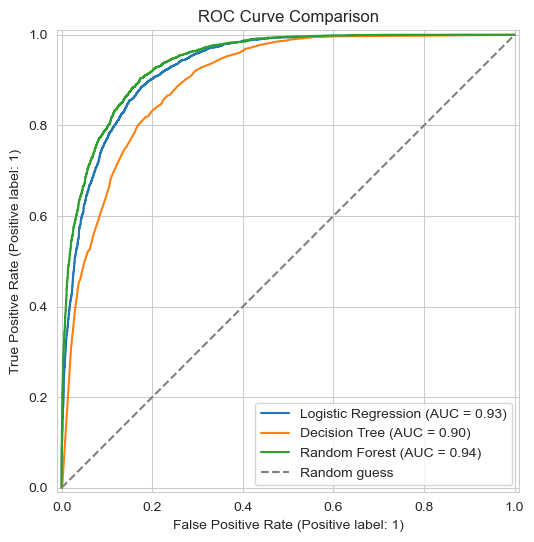

In [30]:
fig, ax = plt.subplots(figsize=(7,6))
RocCurveDisplay.from_predictions(y_test, prob_lr, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, prob_dt, name="Decision Tree", ax=ax)
RocCurveDisplay.from_predictions(y_test, prob_rf, name="Random Forest", ax=ax)
ax.plot([0,1],[0,1], linestyle='--', color='gray', label='Random guess')
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.show()

**🔍 Insight:** All three curves bow well above the diagonal 'random guess' line, confirming each model has real predictive power. Random Forest's curve sits closest to the top-left corner, visually confirming it's the strongest model of the three.

## Feature Importance Analysis

We examine the Random Forest model's feature importance scores to identify which input variables contribute most to its predictions. This helps us understand the factors the model considers most useful when predicting placement outcomes.

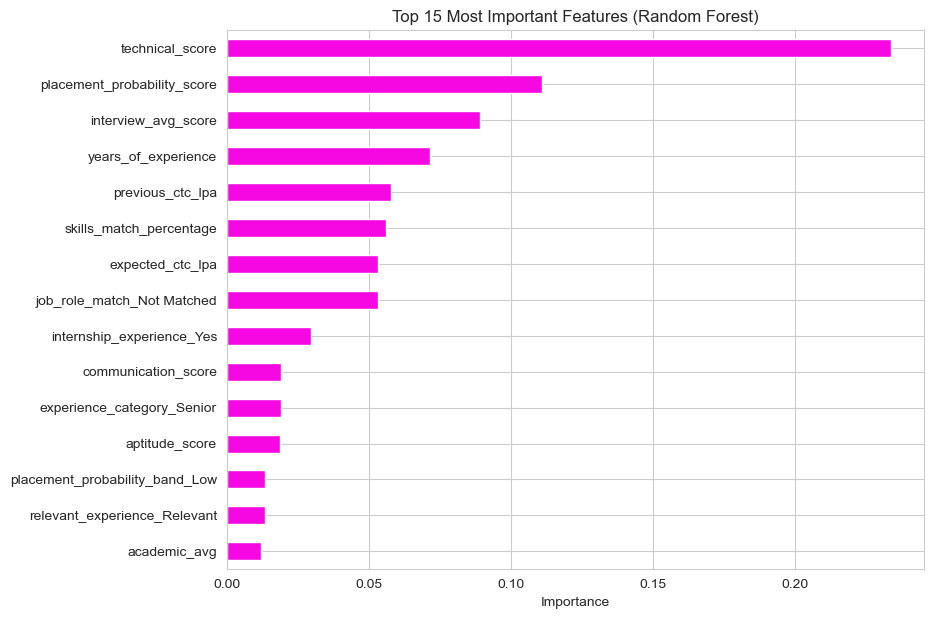

technical_score                   0.233690
placement_probability_score       0.110760
interview_avg_score               0.088933
years_of_experience               0.071488
previous_ctc_lpa                  0.057632
skills_match_percentage           0.056021
expected_ctc_lpa                  0.053311
job_role_match_Not Matched        0.053054
internship_experience_Yes         0.029501
communication_score               0.019183
experience_category_Senior        0.018999
aptitude_score                    0.018780
placement_probability_band_Low    0.013327
relevant_experience_Relevant      0.013273
academic_avg                      0.012084
dtype: float64

In [29]:
feature_importance = pd.Series(rforest.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(9,7))
feature_importance.sort_values().plot(kind='barh', color="#F608E2")
plt.title("Top 15 Most Important Features (Random Forest)")
plt.xlabel("Importance")
plt.show()

feature_importance

**Key takeaways:**
- **Technical score** is by far the strongest driver of whether a candidate accepts a placement.
- **Years of experience** and **skills match %** are also strong predictors.
- Whether the candidate's **experience level is Senior**, and whether the **job role matched**
  their profile, matter a lot too.
- **Expected CTC** (salary expectation) plays a meaningful role — mismatched salary expectations
  likely lead to more offer rejections.

## Business Insights & Recommendations

Based on the EDA and the model's feature importance, here are actionable takeaways:

1. **Prioritize candidates with strong technical scores** — they are consistently more likely
   to accept offers, so screening should weight this heavily.
2. **Watch salary expectation mismatch** (`expected_ctc_lpa` vs `previous_ctc_lpa`) — large gaps
   may signal a candidate who will reject the offer; align expectations early in the process.
3. **High-competition roles have lower acceptance rates** — for these roles, consider having
   backup candidates ready or streamlining decision speed to close before competitors do.
4. **Tier 1 companies see different acceptance dynamics than Tier 3** — tailor negotiation and
   engagement strategy by company tier.
5. **Candidates flagged as "High-Risk"** (weak interview performance + low skills match + high
   competition) should get extra engagement/follow-up from recruiters to reduce drop-off.

In [31]:
df.to_csv("cleaned_job_placement_data_after_ml.csv", index=False)
print("Saved cleaned_job_placement_data_after_ml.csv ✅  Shape:", df.shape)

Saved cleaned_job_placement_data_after_ml.csv ✅  Shape: (50000, 35)


## Save the trained model (`model.pkl`)

We save the **Random Forest** model (our best performer) along with the scaler
and the exact list of feature columns used during training. This lets us reload
the model later and make predictions on new candidates without retraining.


In [32]:
model_package = {
    "model": rforest,
    "scaler": scaler,
    "feature_columns": list(X.columns),
    "numeric_feature_columns": numeric_feature_cols,
}

with open("model.pkl", "wb") as f:
    pickle.dump(model_package, f)

print("Saved model.pkl ✅")
print(f"Model: RandomForestClassifier | Features used: {len(X.columns)}")


Saved model.pkl ✅
Model: RandomForestClassifier | Features used: 43
